# Vẽ đường đồng mức của hàm mất mát MSE và quỹ đạo Gradient Descent (mục 5.1.4)

Dữ liệu: 1000 điểm gần đường thẳng y = 4 + 3x; khởi tạo w = (2, 1); η = 1 và η = 0.1

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

np.random.seed(2)
X = np.random.rand(1000)
y = 4 + 3 * X + .2 * np.random.randn(1000)
Xbar = np.column_stack([np.ones(len(X)), X])
w_ols = np.linalg.pinv(Xbar.T @ Xbar) @ Xbar.T @ y   # nghiệm OLS để so sánh

def cost(w):
    """Hàm mất mát L(w) = 1/(2N) ||Xbar w - y||^2."""
    return .5 / len(y) * np.sum((Xbar @ w - y)**2)

def grad(w):
    """Gradient của L(w)."""
    return Xbar.T @ (Xbar @ w - y) / len(y)

def gd(eta, n_iters=100):
    """Chạy GD từ w = (2, 1), trả về dãy w qua các vòng lặp."""
    w = np.array([2., 1.])
    history = [w]
    for _ in range(n_iters):
        w = w - eta * grad(w)
        history.append(w)
    return np.array(history)

Lưới (w0, w1) để vẽ đường đồng mức

In [2]:
W0, W1 = np.meshgrid(np.linspace(1.5, 6.5, 200), np.linspace(0.5, 5, 200))
L = np.array([[cost(np.array([a, b])) for a, b in zip(r0, r1)] for r0, r1 in zip(W0, W1)])

Vẽ hình và lưu ảnh.

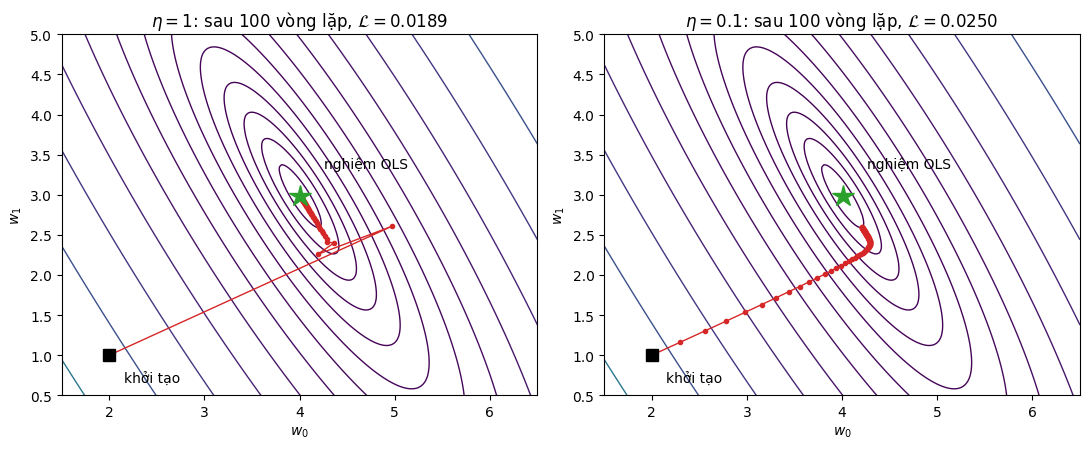

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, eta in zip(axes, [1, 0.1]):
    w_path = gd(eta)                           # quỹ đạo của w
    ax.contour(W0, W1, L, levels=np.logspace(-1.6, 1.2, 15), cmap="viridis", linewidths=1)
    ax.plot(w_path[:, 0], w_path[:, 1], "o-", color="#D62728", ms=3, lw=1)
    ax.plot(2, 1, "ks", ms=8); ax.annotate("khởi tạo", (2, 1), (2.15, 0.65))
    ax.plot(w_ols[0], w_ols[1], "*", color="#2CA02C", ms=16)
    ax.annotate("nghiệm OLS", w_ols, (w_ols[0] + 0.25, w_ols[1] + 0.35))
    ax.set_xlabel("$w_0$"); ax.set_ylabel("$w_1$")
    ax.set_title(f"$\\eta = {eta}$: sau 100 vòng lặp, $\\mathcal{{L}} = {cost(w_path[-1]):.4f}$")
fig.tight_layout()
fig.savefig(IMAGES / "contours.png", dpi=150)